In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from scipy.sparse import hstack, load_npz
import joblib
import warnings
warnings.filterwarnings('ignore')

# ── Device configuration ────────────────────────────────────
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
NUM_GPUS = torch.cuda.device_count()

print(f"Device: {device}")
print(f"PyTorch version: {torch.__version__}")
print(f"GPU count: {NUM_GPUS}")

if torch.cuda.is_available():
    for i in range(NUM_GPUS):
        print(f"GPU {i}: {torch.cuda.get_device_name(i)}")

INPUT_PATH = "/kaggle/input/notebooks/catalinagligor22/02-preprocessing/"
OUTPUT_DIR = "/kaggle/working/"

# Images + masks
X_train_img = np.load(INPUT_PATH + 'X_train_img.npy')
X_val_img = np.load(INPUT_PATH + 'X_val_img.npy')
X_test_img = np.load(INPUT_PATH + 'X_test_img.npy')
y_train_img = np.load(INPUT_PATH + 'y_train_img.npy')
y_val_img = np.load(INPUT_PATH + 'y_val_img.npy')
y_test_img = np.load(INPUT_PATH + 'y_test_img.npy')

# Clinical data
df_train = pd.read_csv(INPUT_PATH + 'clinical_train.csv')
df_val = pd.read_csv(INPUT_PATH + 'clinical_val.csv')
df_test = pd.read_csv(INPUT_PATH + 'clinical_test.csv')

# Transformers
preprocessor = joblib.load(INPUT_PATH + 'preprocessor.pkl')
tfidf = joblib.load(INPUT_PATH + 'tfidf_vectorizer.pkl')

print("Data loaded successfully!")
print(f" Images train: {X_train_img.shape}")
print(f" Masks train: {y_train_img.shape}")
print(f" Patients train: {len(df_train)}")
print(f" Patients val: {len(df_val)}")

Device: cuda
PyTorch version: 2.10.0+cu128
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4
Data loaded successfully!
 Images train: (3080, 256, 256)
 Masks train: (3080, 256, 256)
 Patients train: 47926
 Patients val: 10270


In [2]:
# Images + masks
X_train_img = np.load(INPUT_PATH + 'X_train_img.npy')
X_val_img   = np.load(INPUT_PATH + 'X_val_img.npy')
X_test_img  = np.load(INPUT_PATH + 'X_test_img.npy')
y_train_img = np.load(INPUT_PATH + 'y_train_img.npy')
y_val_img   = np.load(INPUT_PATH + 'y_val_img.npy')
y_test_img  = np.load(INPUT_PATH + 'y_test_img.npy')

# Clinical data
df_train = pd.read_csv(INPUT_PATH + 'clinical_train.csv')
df_val   = pd.read_csv(INPUT_PATH + 'clinical_val.csv')
df_test  = pd.read_csv(INPUT_PATH + 'clinical_test.csv')

# Transformers
preprocessor = joblib.load(INPUT_PATH + 'preprocessor.pkl')
tfidf        = joblib.load(INPUT_PATH + 'tfidf_vectorizer.pkl')

print(" Data loaded successfully!")
print(f"   Images train:  {X_train_img.shape}")
print(f"   Masks train:   {y_train_img.shape}")
print(f"   Patients train: {len(df_train)}")
print(f"   Patients val:   {len(df_val)}")

 Data loaded successfully!
   Images train:  (3080, 256, 256)
   Masks train:   (3080, 256, 256)
   Patients train: 47926
   Patients val:   10270


In [3]:
class CarotidDataset(Dataset):
    """
    Custom PyTorch Dataset for carotid ultrasound images.
    Adds channel dimension required by CNN: (N, 256, 256) → (N, 1, 256, 256)
    """
    def __init__(self, images, masks):
        self.images = torch.tensor(images, dtype=torch.float32).unsqueeze(1)
        self.masks = torch.tensor(masks, dtype=torch.float32).unsqueeze(1)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        return self.images[idx], self.masks[idx]

BATCH_SIZE = 16   # try 24 or 32 if memory allows

train_dataset = CarotidDataset(X_train_img, y_train_img)
val_dataset = CarotidDataset(X_val_img, y_val_img)
test_dataset = CarotidDataset(X_test_img, y_test_img)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoader created!")
print(f" Batch size: {BATCH_SIZE}")
print(f" Train batches: {len(train_loader)}")
print(f" Val batches: {len(val_loader)}")

DataLoader created!
 Batch size: 16
 Train batches: 193
 Val batches: 42


In [4]:
class DoubleConv(nn.Module):
    """Basic U-Net block: Conv → BN → ReLU → Conv → BN → ReLU"""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    """
    U-Net for carotid artery segmentation.
    Input: (B, 1, 256, 256)
    Output: (B, 1, 256, 256)
    """
    def __init__(self, features=[64, 128, 256, 512]):
        super().__init__()

        self.encoders = nn.ModuleList()
        self.pools = nn.ModuleList()
        in_ch = 1

        for f in features:
            self.encoders.append(DoubleConv(in_ch, f))
            self.pools.append(nn.MaxPool2d(2))
            in_ch = f

        self.bottleneck = DoubleConv(features[-1], features[-1] * 2)

        self.upconvs = nn.ModuleList()
        self.decoders = nn.ModuleList()

        for f in reversed(features):
            self.upconvs.append(nn.ConvTranspose2d(f * 2, f, 2, stride=2))
            self.decoders.append(DoubleConv(f * 2, f))

        self.output = nn.Conv2d(features[0], 1, 1)

    def forward(self, x):
        skip_connections = []

        for encoder, pool in zip(self.encoders, self.pools):
            x = encoder(x)
            skip_connections.append(x)
            x = pool(x)

        x = self.bottleneck(x)
        skip_connections = skip_connections[::-1]

        for upconv, decoder, skip in zip(self.upconvs, self.decoders, skip_connections):
            x = upconv(x)
            x = torch.cat([skip, x], dim=1)
            x = decoder(x)

        return torch.sigmoid(self.output(x))


model = UNet()

if NUM_GPUS >= 2:
    print("Using U-Net on 2 GPUs with DataParallel")
    model = nn.DataParallel(model, device_ids=[0, 1])

model = model.to(device)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"U-Net created! Trainable parameters: {total_params:,}")

Using U-Net on 2 GPUs with DataParallel
U-Net created! Trainable parameters: 31,036,481


In [5]:
class AttentionBlock(nn.Module):
    def __init__(self, g_ch, x_ch, inter_ch):
        super().__init__()
        self.W_g = nn.Sequential(
            nn.Conv2d(g_ch, inter_ch, kernel_size=1, bias=False),
            nn.BatchNorm2d(inter_ch)
        )
        self.W_x = nn.Sequential(
            nn.Conv2d(x_ch, inter_ch, kernel_size=1, bias=False),
            nn.BatchNorm2d(inter_ch)
        )
        self.psi = nn.Sequential(
            nn.Conv2d(inter_ch, 1, kernel_size=1, bias=True),
            nn.BatchNorm2d(1),
            nn.Sigmoid()
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)
        return x * psi


class AttentionUNet(nn.Module):
    def __init__(self, features=[64, 128, 256, 512]):
        super().__init__()

        self.encoders = nn.ModuleList()
        self.pools = nn.ModuleList()

        in_ch = 1
        for f in features:
            self.encoders.append(DoubleConv(in_ch, f))
            self.pools.append(nn.MaxPool2d(2))
            in_ch = f

        self.bottleneck = DoubleConv(features[-1], features[-1] * 2)

        self.upconvs = nn.ModuleList()
        self.attentions = nn.ModuleList()
        self.decoders = nn.ModuleList()

        for f in reversed(features):
            self.upconvs.append(nn.ConvTranspose2d(f * 2, f, kernel_size=2, stride=2))
            self.attentions.append(AttentionBlock(g_ch=f, x_ch=f, inter_ch=f // 2))
            self.decoders.append(DoubleConv(f * 2, f))

        self.output = nn.Conv2d(features[0], 1, kernel_size=1)

    def forward(self, x):
        skips = []

        for encoder, pool in zip(self.encoders, self.pools):
            x = encoder(x)
            skips.append(x)
            x = pool(x)

        x = self.bottleneck(x)
        skips = skips[::-1]

        for upconv, attn, decoder, skip in zip(self.upconvs, self.attentions, self.decoders, skips):
            x = upconv(x)
            skip = attn(g=x, x=skip)
            x = torch.cat([skip, x], dim=1)
            x = decoder(x)

        return torch.sigmoid(self.output(x))


att_model = AttentionUNet()

if NUM_GPUS >= 2:
    print("Using Attention U-Net on 2 GPUs with DataParallel")
    att_model = nn.DataParallel(att_model, device_ids=[0, 1])

att_model = att_model.to(device)

att_params = sum(p.numel() for p in att_model.parameters() if p.requires_grad)
print(f"Attention U-Net created! Trainable parameters: {att_params:,}")

Using Attention U-Net on 2 GPUs with DataParallel
Attention U-Net created! Trainable parameters: 31,387,053


In [6]:
def dice_loss(pred, target, smooth=1e-6):
    pred_flat = pred.view(-1)
    target_flat = target.view(-1)
    intersection = (pred_flat * target_flat).sum()
    return 1 - (2. * intersection + smooth) / (pred_flat.sum() + target_flat.sum() + smooth)

def combined_loss(pred, target):
    bce = nn.BCELoss()(pred, target)
    dice = dice_loss(pred, target)
    return bce + dice

def dice_score(pred, target, threshold=0.5):
    pred_bin = (pred > threshold).float()
    smooth = 1e-6
    intersection = (pred_bin * target).sum()
    return ((2. * intersection + smooth) / (pred_bin.sum() + target.sum() + smooth)).item()

optimizer = optim.Adam(model.parameters(), lr=1e-3)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=3, factor=0.5)

EPOCHS = 30
train_losses, val_losses = [], []
train_dices, val_dices = [], []
best_val_dice = 0.0

print(f"Starting U-Net training for {EPOCHS} epochs...\n")

for epoch in range(EPOCHS):
    model.train()
    train_loss, train_dice = 0.0, 0.0

    for imgs, masks in train_loader:
        imgs = imgs.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad()
        preds = model(imgs)
        loss = combined_loss(preds, masks)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        train_dice += dice_score(preds.detach().cpu(), masks.detach().cpu())

    model.eval()
    val_loss, val_dice = 0.0, 0.0

    with torch.no_grad():
        for imgs, masks in val_loader:
            imgs = imgs.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            preds = model(imgs)
            val_loss += combined_loss(preds, masks).item()
            val_dice += dice_score(preds.cpu(), masks.cpu())

    tl = train_loss / len(train_loader)
    vl = val_loss / len(val_loader)
    td = train_dice / len(train_loader)
    vd = val_dice / len(val_loader)

    train_losses.append(tl)
    val_losses.append(vl)
    train_dices.append(td)
    val_dices.append(vd)

    scheduler.step(vl)

    if vd > best_val_dice:
        best_val_dice = vd
        torch.save(
            model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict(),
            OUTPUT_DIR + 'unet_best.pth'
        )

    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1:02d}/{EPOCHS} | "
              f"Loss: {tl:.4f}/{vl:.4f} | "
              f"Dice: {td:.4f}/{vd:.4f} | "
              f"LR: {optimizer.param_groups[0]['lr']:.6f}")

print(f"\n✅ U-Net training completed! Best Val Dice: {best_val_dice:.4f}")

Starting U-Net training for 30 epochs...

Epoch 05/30 | Loss: 0.0664/0.0678 | Dice: 0.9478/0.9465 | LR: 0.001000
Epoch 10/30 | Loss: 0.0491/0.0509 | Dice: 0.9604/0.9588 | LR: 0.001000
Epoch 15/30 | Loss: 0.0485/0.0508 | Dice: 0.9607/0.9588 | LR: 0.001000
Epoch 20/30 | Loss: 0.0431/0.0449 | Dice: 0.9649/0.9633 | LR: 0.001000
Epoch 25/30 | Loss: 0.0400/0.0456 | Dice: 0.9674/0.9626 | LR: 0.001000
Epoch 30/30 | Loss: 0.0382/0.0430 | Dice: 0.9688/0.9648 | LR: 0.001000

✅ U-Net training completed! Best Val Dice: 0.9651


In [7]:
optimizer_att = optim.Adam(att_model.parameters(), lr=1e-3)
scheduler_att = optim.lr_scheduler.ReduceLROnPlateau(optimizer_att, patience=3, factor=0.5)

att_train_losses, att_val_losses = [], []
att_train_dices, att_val_dices = [], []
best_att_val_dice = 0.0

print(f"Starting Attention U-Net training for {EPOCHS} epochs...\n")

for epoch in range(EPOCHS):
    att_model.train()
    train_loss, train_dice = 0.0, 0.0

    for imgs, masks in train_loader:
        imgs = imgs.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer_att.zero_grad()
        preds = att_model(imgs)
        loss = combined_loss(preds, masks)
        loss.backward()
        optimizer_att.step()

        train_loss += loss.item()
        train_dice += dice_score(preds.detach().cpu(), masks.detach().cpu())

    att_model.eval()
    val_loss, val_dice = 0.0, 0.0

    with torch.no_grad():
        for imgs, masks in val_loader:
            imgs = imgs.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            preds = att_model(imgs)
            val_loss += combined_loss(preds, masks).item()
            val_dice += dice_score(preds.cpu(), masks.cpu())

    tl = train_loss / len(train_loader)
    vl = val_loss / len(val_loader)
    td = train_dice / len(train_loader)
    vd = val_dice / len(val_loader)

    att_train_losses.append(tl)
    att_val_losses.append(vl)
    att_train_dices.append(td)
    att_val_dices.append(vd)

    scheduler_att.step(vl)

    if vd > best_att_val_dice:
        best_att_val_dice = vd
        torch.save(
            att_model.module.state_dict() if isinstance(att_model, nn.DataParallel) else att_model.state_dict(),
            OUTPUT_DIR + 'attention_unet_best.pth'
        )

    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1:02d}/{EPOCHS} | "
              f"Loss: {tl:.4f}/{vl:.4f} | "
              f"Dice: {td:.4f}/{vd:.4f} | "
              f"LR: {optimizer_att.param_groups[0]['lr']:.6f}")

print(f"\n✅ Attention U-Net training completed! Best Val Dice: {best_att_val_dice:.4f}")

Starting Attention U-Net training for 30 epochs...

Epoch 05/30 | Loss: 0.0650/0.0678 | Dice: 0.9496/0.9466 | LR: 0.001000
Epoch 10/30 | Loss: 0.0524/0.0521 | Dice: 0.9578/0.9581 | LR: 0.001000
Epoch 15/30 | Loss: 0.0458/0.0450 | Dice: 0.9628/0.9633 | LR: 0.001000
Epoch 20/30 | Loss: 0.0430/0.0467 | Dice: 0.9649/0.9619 | LR: 0.001000
Epoch 25/30 | Loss: 0.0375/0.0401 | Dice: 0.9694/0.9672 | LR: 0.000500
Epoch 30/30 | Loss: 0.0343/0.0407 | Dice: 0.9721/0.9668 | LR: 0.000500

✅ Attention U-Net training completed! Best Val Dice: 0.9676


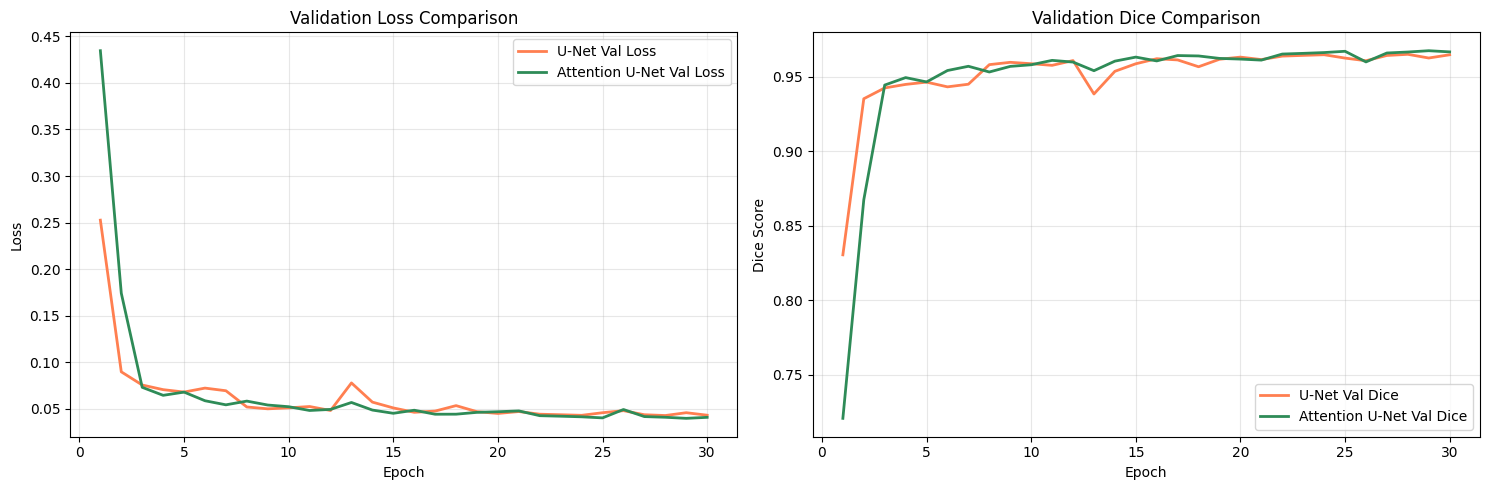

✅ Comparative chart saved!


In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
epochs_range = range(1, EPOCHS + 1)

ax1.plot(epochs_range, val_losses, label='U-Net Val Loss', linewidth=2, color='coral')
ax1.plot(epochs_range, att_val_losses, label='Attention U-Net Val Loss', linewidth=2, color='seagreen')
ax1.set_title('Validation Loss Comparison')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(epochs_range, val_dices, label='U-Net Val Dice', linewidth=2, color='coral')
ax2.plot(epochs_range, att_val_dices, label='Attention U-Net Val Dice', linewidth=2, color='seagreen')
ax2.set_title('Validation Dice Comparison')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Dice Score')
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR + 'unet_vs_attention_unet.png', dpi=150)
plt.show()

print("✅ Comparative chart saved!")

In [9]:
seg_results = pd.DataFrame({
    "Model": ["U-Net", "Attention U-Net"],
    "Best Val Dice": [best_val_dice, best_att_val_dice],
    "Last Train Loss": [train_losses[-1], att_train_losses[-1]],
    "Last Val Loss": [val_losses[-1], att_val_losses[-1]],
    "Params": [total_params, att_params]
})

print("=" * 75)
print("SEGMENTATION MODELS COMPARISON")
print("=" * 75)
print(seg_results.to_string(index=False))
print("=" * 75)

best_model_name = seg_results.sort_values("Best Val Dice", ascending=False).iloc[0]["Model"]
print(f"\nSelected model for segmentation: {best_model_name}")

seg_results.to_csv(OUTPUT_DIR + "segmentation_model_comparison.csv", index=False)

SEGMENTATION MODELS COMPARISON
          Model  Best Val Dice  Last Train Loss  Last Val Loss   Params
          U-Net       0.965149         0.038184       0.042963 31036481
Attention U-Net       0.967571         0.034290       0.040660 31387053

Selected model for segmentation: Attention U-Net


In [10]:
# Prepare clinical features
numeric_features   = ['age_years', 'ap_hi', 'ap_lo', 'bmi', 'pulse_pressure']
categorical_features = ['gender', 'cholesterol', 'gluc', 'smoke', 'alco', 'active']

X_train_tab = preprocessor.transform(df_train[numeric_features + categorical_features])
X_val_tab   = preprocessor.transform(df_val[numeric_features + categorical_features])

X_train_tfidf = tfidf.transform(df_train['risk_text'])
X_val_tfidf   = tfidf.transform(df_val['risk_text'])

X_train_clin = hstack([X_train_tab, X_train_tfidf])
X_val_clin   = hstack([X_val_tab,   X_val_tfidf])

y_train_clin = df_train['cardio'].values
y_val_clin   = df_val['cardio'].values

# ── Model 1: XGBoost ──────────────────────────────────────
print("Training XGBoost...")
xgb = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=42,
    device='cpu'
)
xgb.fit(X_train_clin, y_train_clin,
        eval_set=[(X_val_clin, y_val_clin)],
        verbose=50)

xgb_acc = accuracy_score(y_val_clin, xgb.predict(X_val_clin))
xgb_f1  = f1_score(y_val_clin,       xgb.predict(X_val_clin))
xgb_auc = roc_auc_score(y_val_clin,  xgb.predict_proba(X_val_clin)[:, 1])
print(f"\n XGBoost — Acc: {xgb_acc:.4f} | F1: {xgb_f1:.4f} | AUC: {xgb_auc:.4f}")

# ── Model 2: Logistic Regression (baseline) ──────────────
print("\nTraining Logistic Regression (baseline)...")
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_clin, y_train_clin)

lr_acc = accuracy_score(y_val_clin, lr.predict(X_val_clin))
lr_f1  = f1_score(y_val_clin,       lr.predict(X_val_clin))
lr_auc = roc_auc_score(y_val_clin,  lr.predict_proba(X_val_clin)[:, 1])
print(f" Logistic Regression — Acc: {lr_acc:.4f} | F1: {lr_f1:.4f} | AUC: {lr_auc:.4f}")

Training XGBoost...
[0]	validation_0-logloss:0.67993
[50]	validation_0-logloss:0.54377
[100]	validation_0-logloss:0.54098
[150]	validation_0-logloss:0.54130
[200]	validation_0-logloss:0.54148
[250]	validation_0-logloss:0.54174
[299]	validation_0-logloss:0.54232

 XGBoost — Acc: 0.7334 | F1: 0.7183 | AUC: 0.8014

Training Logistic Regression (baseline)...
 Logistic Regression — Acc: 0.7310 | F1: 0.7122 | AUC: 0.7935


In [11]:
results = pd.DataFrame({
    'Model':    ['XGBoost', 'Logistic Regression'],
    'Accuracy': [xgb_acc,  lr_acc],
    'F1-Score': [xgb_f1,   lr_f1],
    'AUC-ROC':  [xgb_auc,  lr_auc]
})

print("=" * 55)
print("CLINICAL MODELS COMPARISON TABLE")
print("=" * 55)
print(results.to_string(index=False))
print("=" * 55)
print(f"\nSelected model: XGBoost (higher AUC: {xgb_auc:.4f})")

CLINICAL MODELS COMPARISON TABLE
              Model  Accuracy  F1-Score  AUC-ROC
            XGBoost  0.733398  0.718313 0.801392
Logistic Regression  0.730964  0.712158 0.793468

Selected model: XGBoost (higher AUC: 0.8014)


In [12]:
# Save models

torch.save(
    model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict(),
    OUTPUT_DIR + 'unet_final.pth'
)

torch.save(
    att_model.module.state_dict() if isinstance(att_model, nn.DataParallel) else att_model.state_dict(),
    OUTPUT_DIR + 'attention_unet_final.pth'
)

joblib.dump(xgb, OUTPUT_DIR + 'xgboost_model.pkl')
joblib.dump(lr, OUTPUT_DIR + 'logistic_regression.pkl')

results.to_csv(OUTPUT_DIR + 'model_comparison.csv', index=False)

print("Models saved to Output:")
print(" unet_best.pth ← best U-Net")
print(" unet_final.pth ← final U-Net")
print(" attention_unet_best.pth ← best Attention U-Net")
print(" attention_unet_final.pth ← final Attention U-Net")
print(" segmentation_model_comparison.csv ← segmentation comparison")
print(" unet_training_curves.png ← U-Net training curves")
print(" unet_vs_attention_unet.png ← curve comparison")
print(" xgboost_model.pkl ← trained XGBoost")
print(" logistic_regression.pkl ← baseline LR")
print(" model_comparison.csv ← clinical comparison table")

Models saved to Output:
 unet_best.pth ← best U-Net
 unet_final.pth ← final U-Net
 attention_unet_best.pth ← best Attention U-Net
 attention_unet_final.pth ← final Attention U-Net
 segmentation_model_comparison.csv ← segmentation comparison
 unet_training_curves.png ← U-Net training curves
 unet_vs_attention_unet.png ← curve comparison
 xgboost_model.pkl ← trained XGBoost
 logistic_regression.pkl ← baseline LR
 model_comparison.csv ← clinical comparison table
